Exploration des données Skill corner

Importation 

In [1]:
import s3fs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fs = s3fs.S3FileSystem(
    endpoint_url="https://minio.lab.sspcloud.fr",
    client_kwargs={"region_name": "us-east-1"},
)

obr = pd.read_parquet("s3://lfaivre/diffusion/aus1league_obraggregates_20242025.parquet", filesystem=fs)
passing = pd.read_parquet("s3://lfaivre/diffusion/aus1league_passingaggregates_20242025.parquet", filesystem=fs)
physical = pd.read_parquet("s3://lfaivre/diffusion/aus1league_physicalaggregates_20242025.parquet", filesystem=fs)

On filtre une première fois par un nombre de matchs minimums fixés à 3 

In [2]:
#on garde uniquement les joueurs à plus de 3 matchs (skill corner conseille de prendre 5 donc à voir)
MIN_MATCHES = 3

#on applique le filtre sur les 3 data frames et on en fait une copie 
phys = physical.loc[physical['count_match'] >= MIN_MATCHES].copy()
pas = passing.loc[passing['performance_count'] >= MIN_MATCHES].copy()
courses = obr.loc[obr['performance_count'] >= MIN_MATCHES].copy()

print(physical[['team_name', 'count_match']].head())
print(passing[['team_name', 'performance_count']].head())
print(obr[['team_name', 'performance_count']].head())

                         team_name  count_match
0        Perth Glory Football Club           24
1  Melbourne Victory Football Club            6
2                     Macarthur FC            8
3             Sydney Football Club            4
4             Sydney Football Club            1
                         team_name  performance_count
0        Perth Glory Football Club                 13
1  Melbourne Victory Football Club                  2
2                     Macarthur FC                  7
3             Sydney Football Club                  4
4             Sydney Football Club                  1
                         team_name  performance_count
0        Perth Glory Football Club                 13
1  Melbourne Victory Football Club                  2
2                     Macarthur FC                  7
3             Sydney Football Club                  4
4             Sydney Football Club                  1


On simplifie le nom des équipes pour alléger les sorties

In [3]:
for df in [phys, pas, courses]:
    df['equipe'] = df['team_name'].map(
        lambda s: s.replace(' Football Club', '').replace(' FC', '').strip()
    )


Création de poids statistiques pour tenir compte du temps de jeu ou du nombre d'actions observées car on va calculer des moyennes pondérées par équipe sur les variables où les statistiques sont données par 30 minutes par exemple.

In [4]:
#Statistiques physiques : temps total de jeu
phys['poids'] = phys['minutes_full_all'] * phys['count_match']
#Statistiques physiques : temps en possession
phys['poids_tip'] = phys['minutes_full_tip'] * phys['count_match']
#Statistiques physiques : temps hors possession
phys['poids_otip'] = phys['minutes_full_otip'] * phys['count_match']
#Passes et courses : temps de possession
pas['poids'] = pas['minutes_tip'] * pas['performance_count']
courses['poids'] = courses['minutes_tip'] * courses['performance_count']
#Qualité des passes : nombre de passes tentées
pas['poids_passes'] = pas['pass_count_attempted_total']
#Distance moyenne des courses : nombre de courses
courses['poids_courses'] = courses['offballrun_count_total']

On construit deux fonctions. La première permet de calculer la moyenne pondérée pour chaque équipe. Les observations où l'indicateur est manquant sont exclues du numérateur et du dénominateur. La seconde résume la dispersion entre joueurs d'une même équipe avec la médiane, l'écart-type, le minimum et le maximum
La moyenne pondérée ne doit pas être présentée comme un total collectif de passes ou de courses.

In [5]:
#moyenne pondérée = somme(variable * poids)/somme(poids)
def moyenne_ponderee_par_equipe(df, variables, poids):
    resultat = {}

    for variable in variables:
        valeurs = df[variable].fillna(0) #on gere les valeurs manquantes, on met 0 au lieu de NA ce qui va nous permettre de calculer la somme
        poids_valides = df[poids].fillna(0) * (1 - df[variable].isna().astype(int)) #permet d'exclure les valeurs manquantes de la moyenne pondérée (donne poids*1 lorsque la valeur est là, 0 sinon)
        numerateur = (valeurs * poids_valides).groupby(df['equipe']).sum()
        denominateur = poids_valides.groupby(df['equipe']).sum()
        resultat[variable] = numerateur / denominateur
    return pd.DataFrame(resultat)

#fonction qui permet d'avoir la dispersion des profils de joueurs au sein des équipes
def dispersion_profils(df, variables):
    dispersion = df.groupby('equipe').agg({v: ['median', 'std', 'min', 'max'] for v in variables})
    return dispersion

On choisit les indicateurs qui nous intéressent, comme ceux qui décrivent la circulation du ballon, la capacité à faire progresser le jeu ou les appels sans ballon. On distingue les indicateurs exprimés par 30 minutes de possession de l'équipe aux volumes bruts de saison. 
L’idée est d’observer si Auckland se caractérise par un jeu de passes fourni ou direct, et si les courses de ses joueurs suggèrent beaucoup de solutions de progression. Ces statistiques donnent du contexte à notre future analyse de la zone 14, sans prouver qu’une action est passée par cette zone.

In [6]:
#passes :
variables_passes = [
    'pass_count_attempted_p30tip',            #Passes tentees
    'pass_count_completed_p30tip',            #Passes reussies
    'pass_count_linebreak_attempted_p30tip',  #Passes qui cassent une ligne
    'pass_count_linebreak_completed_p30tip',  #Passes reussies qui cassent une ligne
    'pass_count_difficultpass_attempted_p30tip', #Passes difficiles
    'pass_count_longrange_attempted_p30tip',  #Passes longues
    'pass_count_dangerous_attempted_p30tip',  #Passes dangereuses
    'pass_count_shotwithin10s_p30tip'         #Passes suivies d'un tir sous 10 s
]
variables_qualite = [
    'pass_pct_completed',                     #Taux de passes reussies
    'pass_avgdistance'                        #Distance moyenne des passes
]

#courses :
variables_courses = [
    'offballrun_count_p30tip',                #Toutes les courses sans ballon
    'offballrun_count_dangerous_p30tip',      #Courses dangereuses
    'offballrun_count_targeted_p30tip',       #Courses visees par une passe
    'offballrun_count_received_p30tip',       #Courses avec reception
    'offballrun_count_penaltyarea_p30tip',    #Courses dans la surface
    'offballrun_count_abovehsr_p30tip'        #Courses au-dessus du seuil HSR
]

#Statistiques physiques : ensemble du temps de jeu
variables_physiques = [
    'total_metersperminute_full_all',
    'hsr_distance_full_all'
]

#Statistiques physiques : en possession du ballon
variables_physiques_tip = [
    'total_metersperminute_full_tip'
]
#Statistiques physiques : hors possession du ballon
variables_physiques_otip = [
    'total_metersperminute_full_otip'
]

On a pour objectif de faire un tableau descriptif par équipe.
On applique les pondérations aux familles d'indicateurs puis on réalise des jointures pour réunir les statistiques dans un même tableau.
On calcule aussi des proportions notamment sur le type de courses et le type de passes.
On rajoute des variables de types de courses pour s'interroger sur l'utilisation de la zone 14.

In [7]:
#calcul des moyennes pondérées par équipes
tab_passes = moyenne_ponderee_par_equipe(pas, variables_passes, 'poids')
tab_qualite = moyenne_ponderee_par_equipe(pas, variables_qualite, 'poids_passes')
tab_courses = moyenne_ponderee_par_equipe(courses, variables_courses, 'poids')
#Distance moyenne des courses sans ballon
tab_distance_courses = moyenne_ponderee_par_equipe(courses, ['offballrun_avgdistance'], 'poids_courses')
tab_physique = moyenne_ponderee_par_equipe(phys, variables_physiques, 'poids')
tab_physique_tip = moyenne_ponderee_par_equipe(phys, variables_physiques_tip, 'poids_tip')
tab_physique_otip = moyenne_ponderee_par_equipe(phys, variables_physiques_otip, 'poids_otip')

#Types de courses susceptibles d'eclairer le contournement de la zone 14
variables_types = [
    'behindrun_count_p30tip',                 #Courses dans le dos de la defense
    'comingshortrun_count_p30tip',            #Courses en venant court
    'supportrun_count_p30tip',                #Courses de soutien
    'pullingwiderun_count_p30tip',            #Courses ecartant sur l'aile
    'pullinghalfspacerun_count_p30tip'        #Courses vers les demi-espaces
]
tab_types = moyenne_ponderee_par_equipe(courses, variables_types, 'poids') 

#on fusionne les tableaux de moyennes pondérées
equipes = tab_passes.reset_index()
for tableau in [tab_qualite, tab_courses, tab_physique, tab_types, tab_physique_tip, tab_physique_otip, tab_distance_courses]:
    equipes = equipes.merge(tableau.reset_index(), on='equipe', how='outer')

#proportions de passes longues et passes cassant des lignes parmi les passes tentées; courses dangereuses, courses dans le dos de la défense, courses en solution courte parmi les courses
equipes['part_passes_longues'] = (equipes['pass_count_longrange_attempted_p30tip'] / equipes['pass_count_attempted_p30tip'])
equipes['part_passes_lignes'] = (equipes['pass_count_linebreak_attempted_p30tip'] / equipes['pass_count_attempted_p30tip'])
#proportion de passes cassant les lignes qui sont réussies
equipes['reussite_passes_lignes'] = (equipes['pass_count_linebreak_completed_p30tip'] / equipes['pass_count_linebreak_attempted_p30tip'])
#proportion de passes difficiles parmi les passes tentées
equipes['part_passes_difficiles'] = (equipes['pass_count_difficultpass_attempted_p30tip'] / equipes['pass_count_attempted_p30tip'])
equipes['part_courses_dangereuses'] = (equipes['offballrun_count_dangerous_p30tip'] / equipes['offballrun_count_p30tip'])
equipes['part_courses_dos_defense'] = (equipes['behindrun_count_p30tip'] / equipes['offballrun_count_p30tip'])
equipes['part_courses_courtes'] = (equipes['comingshortrun_count_p30tip'] / equipes['offballrun_count_p30tip'])

Comparaison des passes entre équipes

In [8]:
#on affiche les stats descriptives sur les passes 
print('\nTOUTES LES EQUIPES : LES PASSES ')
print(equipes[['equipe'] + variables_passes + variables_qualite + ['part_passes_longues', 'part_passes_lignes', 'reussite_passes_lignes', 'part_passes_difficiles']])


TOUTES LES EQUIPES : LES PASSES 
                      equipe  pass_count_attempted_p30tip  \
0            Adelaide United                    44.691901   
1                   Auckland                    39.978161   
2              Brisbane Roar                    43.238849   
3     Central Coast Mariners                    41.633493   
4                  Macarthur                    42.843069   
5             Melbourne City                    42.977998   
6          Melbourne Victory                    40.673131   
7      Newcastle United Jets                    44.811420   
8                Perth Glory                    42.058424   
9                     Sydney                    44.119142   
10        Wellington Phoenix                    44.229782   
11  Western Sydney Wanderers                    41.620791   
12            Western United                    42.310824   

    pass_count_completed_p30tip  pass_count_linebreak_attempted_p30tip  \
0                     37.627944      

Comparaison des courses sans ballon

In [9]:
#on affiche les stats descriptives sur les courses
print('\nTOUTES LES EQUIPES : COURSES SANS BALLON')
print(equipes[['equipe'] + variables_courses + variables_types + ['part_courses_dangereuses', 'part_courses_dos_defense', 'part_courses_courtes', 'offballrun_avgdistance']])


TOUTES LES EQUIPES : COURSES SANS BALLON
                      equipe  offballrun_count_p30tip  \
0            Adelaide United                21.842777   
1                   Auckland                24.238766   
2              Brisbane Roar                20.985241   
3     Central Coast Mariners                20.791775   
4                  Macarthur                20.685538   
5             Melbourne City                23.709076   
6          Melbourne Victory                22.963723   
7      Newcastle United Jets                22.569720   
8                Perth Glory                21.666861   
9                     Sydney                21.964489   
10        Wellington Phoenix                21.681512   
11  Western Sydney Wanderers                25.244043   
12            Western United                24.095214   

    offballrun_count_dangerous_p30tip  offballrun_count_targeted_p30tip  \
0                            7.324189                          7.679318   
1        

Comparaison de l'activité physique 

In [10]:
#on affiche les stats descriptives sur les données physiques
print('\nTOUTES LES EQUIPES : INTENSITE PHYSIQUE')
print(equipes[['equipe'] + variables_physiques + variables_physiques_tip + variables_physiques_otip ])


TOUTES LES EQUIPES : INTENSITE PHYSIQUE
                      equipe  total_metersperminute_full_all  \
0            Adelaide United                      115.563212   
1                   Auckland                      112.693403   
2              Brisbane Roar                      117.178857   
3     Central Coast Mariners                      113.730201   
4                  Macarthur                      109.050258   
5             Melbourne City                      117.261631   
6          Melbourne Victory                      110.739326   
7      Newcastle United Jets                      115.842207   
8                Perth Glory                      115.453720   
9                     Sydney                      112.873567   
10        Wellington Phoenix                      111.927955   
11  Western Sydney Wanderers                      115.116020   
12            Western United                      118.810320   

    hsr_distance_full_all  total_metersperminute_full_tip  \
0

On cherche à situer où se trouve auckland par rapport à la ligue.
On regarde la dispersion entre les équipes.

In [11]:
#on regarde la distribution entre équipes sur plusieurs stats 
print('\nDISTRIBUTION ENTRE EQUIPES')
variables_clefs = ['pass_count_attempted_p30tip', 'pass_count_linebreak_attempted_p30tip', 'pass_count_difficultpass_attempted_p30tip', 'pass_avgdistance', 'offballrun_count_p30tip', 'offballrun_count_dangerous_p30tip', 'part_passes_longues', 'part_courses_dos_defense', 'reussite_passes_lignes', 'part_passes_difficiles', 'offballrun_avgdistance']
resume_ligue = equipes[variables_clefs].agg(['mean', 'median', 'std', 'min', 'max'])
print(resume_ligue.round(2))


DISTRIBUTION ENTRE EQUIPES
        pass_count_attempted_p30tip  pass_count_linebreak_attempted_p30tip  \
mean                          42.71                                   6.87   
median                        42.84                                   6.88   
std                            1.52                                   0.44   
min                           39.98                                   6.07   
max                           44.81                                   7.65   

        pass_count_difficultpass_attempted_p30tip  pass_avgdistance  \
mean                                         6.77             16.60   
median                                       6.62             16.78   
std                                          0.74              0.54   
min                                          5.77             15.14   
max                                          8.14             17.30   

        offballrun_count_p30tip  offballrun_count_dangerous_p30tip  \
mean  

Nous isolons maintenant Auckland afin de lire ses principaux indicateurs et de les comparer à ceux de la ligue.


In [12]:
#Focus sur Auckland
#on filtre l'équipe dans une variable et on affiche des stats sur auckland
auckland = equipes.loc[equipes['equipe'] == 'Auckland'].copy()
print('\nAUCKLAND : PROFIL GENERAL')
print(auckland[['equipe'] + variables_clefs].round(2))


AUCKLAND : PROFIL GENERAL
     equipe  pass_count_attempted_p30tip  \
1  Auckland                        39.98   

   pass_count_linebreak_attempted_p30tip  \
1                                   6.07   

   pass_count_difficultpass_attempted_p30tip  pass_avgdistance  \
1                                       8.14             16.17   

   offballrun_count_p30tip  offballrun_count_dangerous_p30tip  \
1                    24.24                               6.71   

   part_passes_longues  part_courses_dos_defense  reussite_passes_lignes  \
1                 0.06                      0.06                     0.7   

   part_passes_difficiles  offballrun_avgdistance  
1                     0.2                   13.94  


In [13]:
#Comparaison a la moyenne de ligue pour chaque indicateur
print('\nAUCKLAND COMPARE A LA LIGUE')
for variable in variables_clefs:
    valeur = auckland[variable].iloc[0]
    moyenne = equipes[variable].mean()
    mediane = equipes[variable].median()
    ecart_type = equipes[variable].std()
    print('\n', variable)
    print('Auckland :', round(valeur, 2))
    print('Moyenne ligue :', round(moyenne, 2))
    print('Mediane ligue :', round(mediane, 2))
    print('Ecart-type entre equipes :', round(ecart_type, 2))
    print('Ecart Auckland - moyenne :', round(valeur - moyenne, 2))


AUCKLAND COMPARE A LA LIGUE

 pass_count_attempted_p30tip
Auckland : 39.98
Moyenne ligue : 42.71
Mediane ligue : 42.84
Ecart-type entre equipes : 1.52
Ecart Auckland - moyenne : -2.73

 pass_count_linebreak_attempted_p30tip
Auckland : 6.07
Moyenne ligue : 6.87
Mediane ligue : 6.88
Ecart-type entre equipes : 0.44
Ecart Auckland - moyenne : -0.8

 pass_count_difficultpass_attempted_p30tip
Auckland : 8.14
Moyenne ligue : 6.77
Mediane ligue : 6.62
Ecart-type entre equipes : 0.74
Ecart Auckland - moyenne : 1.37

 pass_avgdistance
Auckland : 16.17
Moyenne ligue : 16.6
Mediane ligue : 16.78
Ecart-type entre equipes : 0.54
Ecart Auckland - moyenne : -0.43

 offballrun_count_p30tip
Auckland : 24.24
Moyenne ligue : 22.5
Mediane ligue : 21.96
Ecart-type entre equipes : 1.45
Ecart Auckland - moyenne : 1.74

 offballrun_count_dangerous_p30tip
Auckland : 6.71
Moyenne ligue : 6.41
Mediane ligue : 6.54
Ecart-type entre equipes : 1.02
Ecart Auckland - moyenne : 0.3

 part_passes_longues
Auckland : 0.0

Visualiser le profil des équipes à l'aide de graphiques.
Graphique du volume de passes.


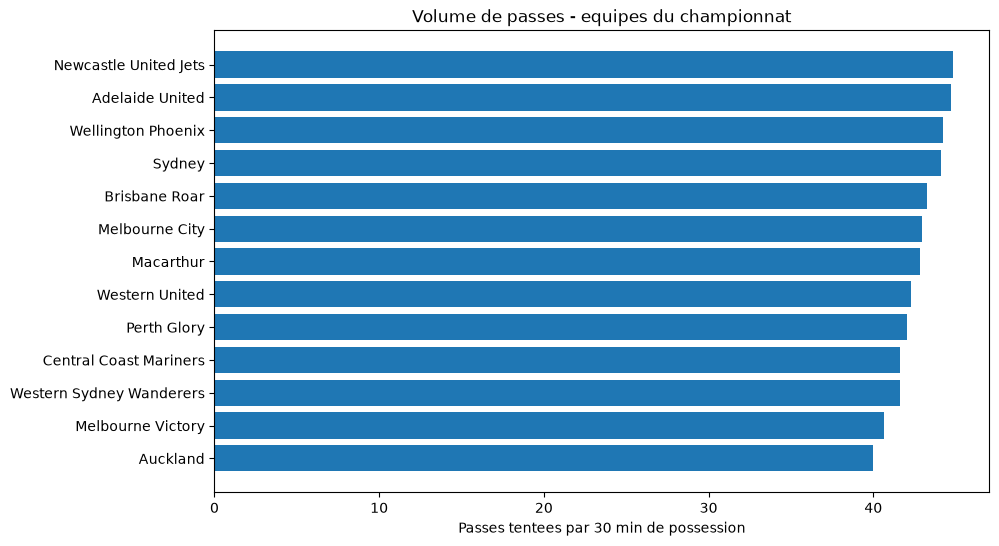

In [14]:
classement = equipes.sort_values('pass_count_attempted_p30tip')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['pass_count_attempted_p30tip'])
plt.xlabel('Passes tentees par 30 min de possession')
plt.title('Volume de passes - equipes du championnat')
plt.show()

Passes difficiles

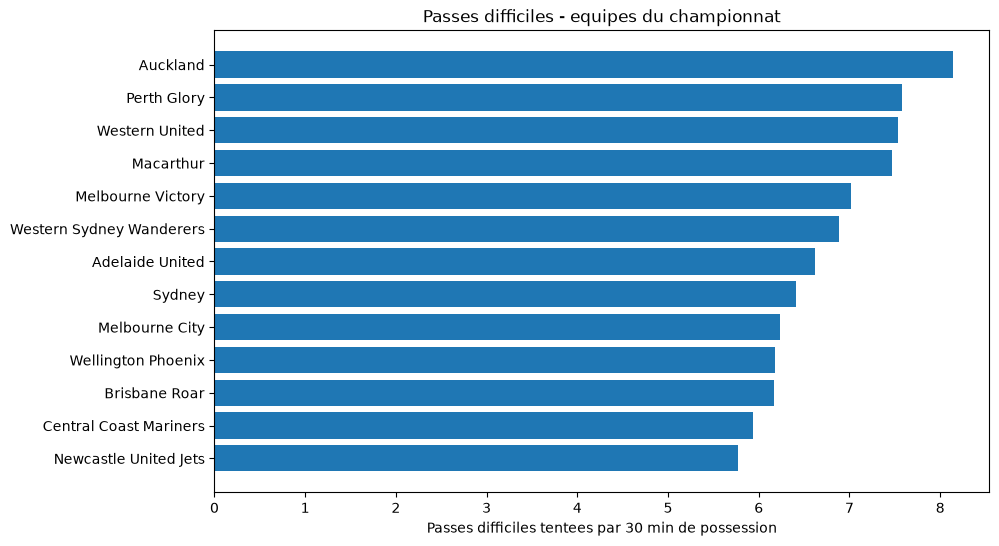

In [15]:
classement = equipes.sort_values('pass_count_difficultpass_attempted_p30tip')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['pass_count_difficultpass_attempted_p30tip'])
plt.xlabel('Passes difficiles tentees par 30 min de possession')
plt.title('Passes difficiles - equipes du championnat')
plt.show()

Volume de courses sans ballon

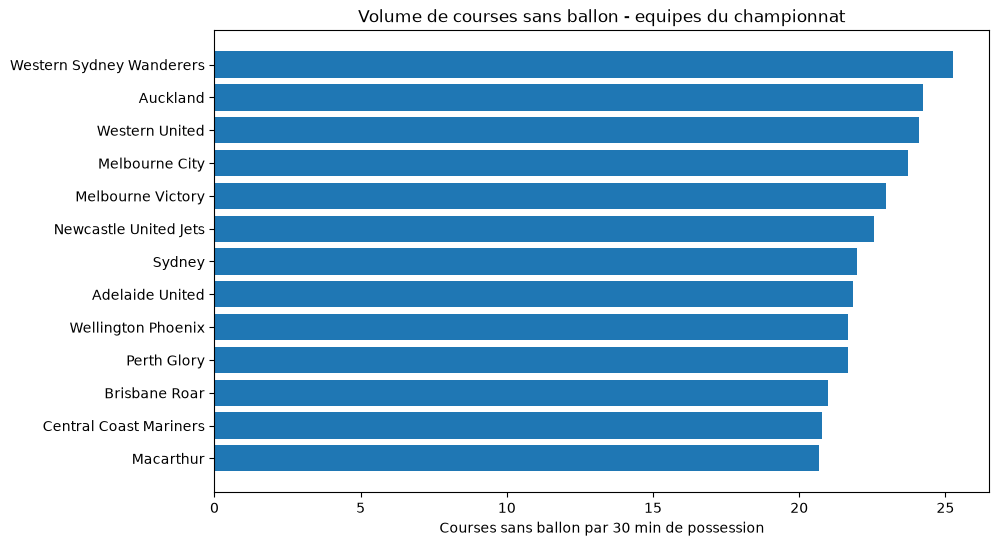

In [16]:
classement = equipes.sort_values('offballrun_count_p30tip')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['offballrun_count_p30tip'])
plt.xlabel('Courses sans ballon par 30 min de possession')
plt.title('Volume de courses sans ballon - equipes du championnat')
plt.show()

Nuage de points passes et courses

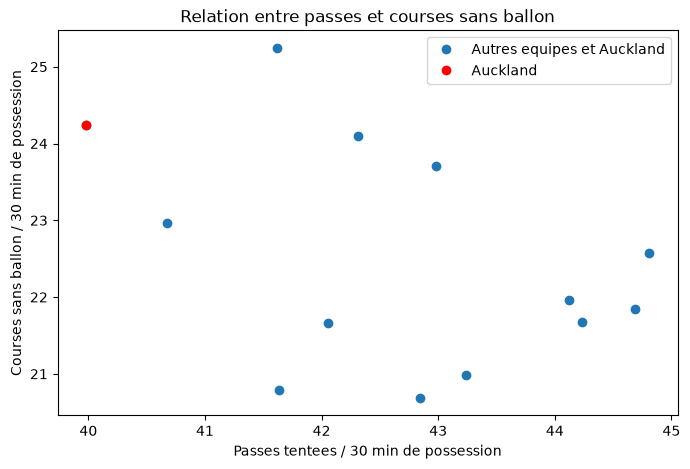

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(equipes['pass_count_attempted_p30tip'],
         equipes['offballrun_count_p30tip'], 'o', label='Autres equipes et Auckland')
plt.plot(auckland['pass_count_attempted_p30tip'],
         auckland['offballrun_count_p30tip'], 'ro', label='Auckland')
plt.xlabel('Passes tentees / 30 min de possession')
plt.ylabel('Courses sans ballon / 30 min de possession')
plt.title('Relation entre passes et courses sans ballon')
plt.legend()
plt.show()

Part des passes longues

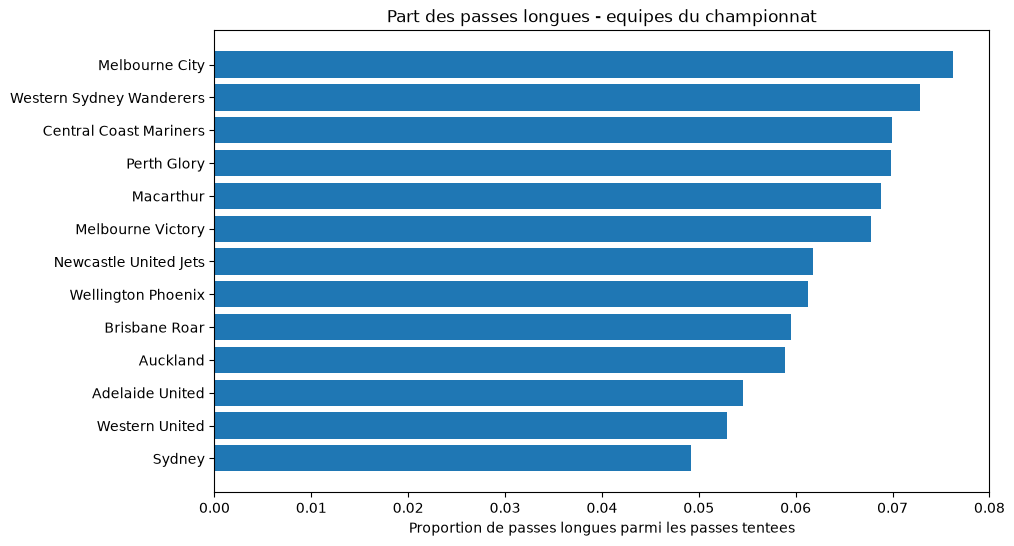

In [18]:
classement = equipes.sort_values('part_passes_longues')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['part_passes_longues'])
plt.xlabel('Proportion de passes longues parmi les passes tentees')
plt.title('Part des passes longues - equipes du championnat')
plt.show()

Part des courses dans le dos de la défense

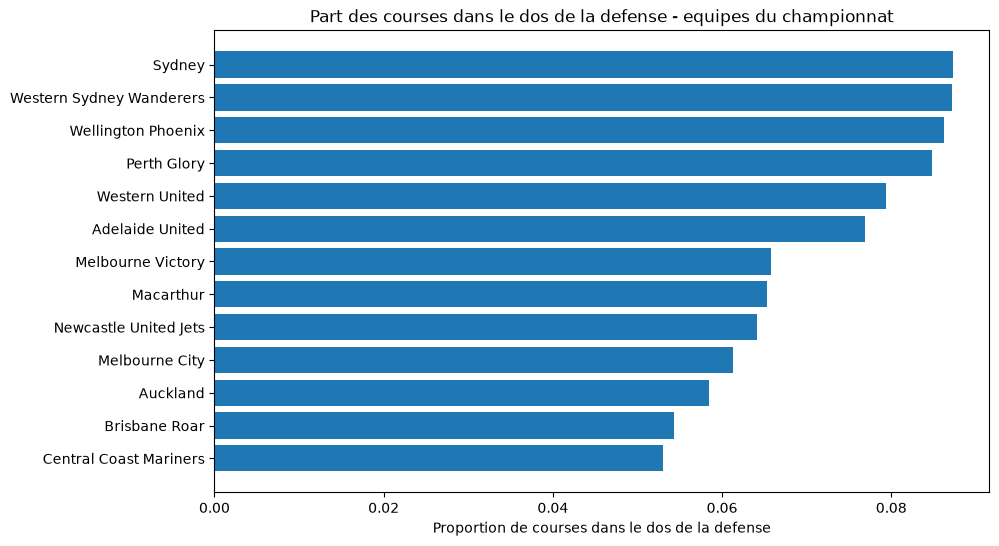

In [19]:
classement = equipes.sort_values('part_courses_dos_defense')
plt.figure(figsize=(10, 6))
plt.barh(classement['equipe'], classement['part_courses_dos_defense'])
plt.xlabel('Proportion de courses dans le dos de la defense')
plt.title('Part des courses dans le dos de la defense - equipes du championnat')
plt.show()

Faire le bilan des stats de Auckland et du profil saison.